# 04 𓏽 Heston: pricing, simulation, VIX and calibration

The Heston model in one walk-through. Three independent pricers must agree; the smile
must respond to each parameter the way the theory says; the Monte Carlo scheme must
reproduce the exact law of the variance; and calibration must recover the parameters
that generated a surface. Each of these is a **check** that raises if it fails.

Maths: [docs/heston.md](../docs/heston.md).

In [1]:
import time
import warnings

import _style as st
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from finpricing import HestonModel, HestonParameters
from finpricing.calibration import HestonCalibrator, OptionSurface
from finpricing.models.heston.vix import vix_coefficients
from finpricing.utils.bs_utils import bs_price, implied_volatility

warnings.filterwarnings("ignore", category=RuntimeWarning)

S0, r, q = 100.0, 0.03, 0.01
base = HestonParameters(v0=0.04, kappa=1.5, theta=0.05, xi=0.6, rho=-0.7)
model = HestonModel(base)
print(base)
print("Feller condition 2κθ ≥ ξ²:", base.feller_satisfied, f"(2κθ = {2 * base.kappa * base.theta:.3f}, ξ² = {base.xi**2:.3f})")

model_type='Heston' v0=0.04 kappa=1.5 theta=0.05 xi=0.6 rho=-0.7
Feller condition 2κθ ≥ ξ²: False (2κθ = 0.150, ξ² = 0.360)


## 1 𓏺 Three pricers, one answer

The Lewis integral (the default), the two FFT pricers and Monte Carlo with Andersen's
QE scheme are independent routes to the same prices. Errors are measured against Lewis.

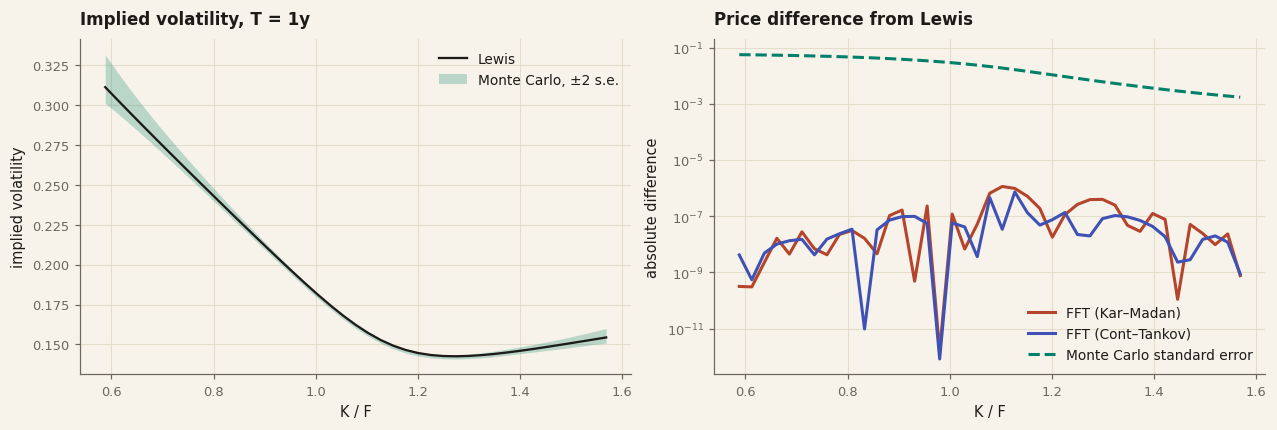

𓋹 PASS  Kar–Madan FFT agrees with Lewis up to grid interpolation (max 1.1e-06)
𓋹 PASS  Cont–Tankov FFT agrees with Lewis up to grid interpolation (max 7.3e-07)
𓋹 PASS  Monte Carlo agrees with Lewis within 4 s.e. (max |z| = 1.84, 0.4s)
𓋹 PASS  put–call parity holds


In [2]:
T = 1.0
strikes = np.linspace(60, 160, 41)
lewis = model.option_price(S0, strikes, T, r, q)
fft = model.option_price(S0, strikes, T, r, q, method="fft")
fft_ct = model.option_price(S0, strikes, T, r, q, method="fft-ct")

start = time.perf_counter()
_, S, _ = model.simulate(S0, T, r, q, n_steps=50, n_paths=100_000, seed=7)
mc_time = time.perf_counter() - start
payoff = np.maximum(S[:, -1, None] - strikes, 0) * np.exp(-r * T)
mc, mc_se = payoff.mean(0), payoff.std(0) / np.sqrt(len(payoff))
del S

forward = S0 * np.exp((r - q) * T)
lewis_iv = implied_volatility(lewis, S0, strikes, T, r, q)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax1.plot(strikes / forward, lewis_iv, color=st.INK, lw=1.5, label="Lewis")
mc_lo = implied_volatility(np.maximum(mc - 2 * mc_se, 1e-12), S0, strikes, T, r, q)
mc_hi = implied_volatility(mc + 2 * mc_se, S0, strikes, T, r, q)
ax1.fill_between(strikes / forward, mc_lo, mc_hi, color=st.VERDIGRIS, alpha=0.25, lw=0,
                 label="Monte Carlo, ±2 s.e.")
ax1.set(title="Implied volatility, T = 1y", xlabel="K / F", ylabel="implied volatility")
ax1.legend()

for values, label, color in [(fft, "FFT (Kar–Madan)", st.OXIDE), (fft_ct, "FFT (Cont–Tankov)", st.INDIGO)]:
    ax2.semilogy(strikes / forward, np.abs(values - lewis) + 1e-16, color=color, label=label)
ax2.semilogy(strikes / forward, mc_se, color=st.VERDIGRIS, ls="--", label="Monte Carlo standard error")
ax2.set(title="Price difference from Lewis", xlabel="K / F", ylabel="absolute difference")
ax2.legend(loc="lower right")
plt.show()

z = (mc - lewis) / mc_se
st.check(np.max(np.abs(fft - lewis)) < 1e-5, f"Kar–Madan FFT agrees with Lewis up to grid interpolation (max {np.max(np.abs(fft - lewis)):.1e})")
st.check(np.max(np.abs(fft_ct - lewis)) < 1e-5, f"Cont–Tankov FFT agrees with Lewis up to grid interpolation (max {np.max(np.abs(fft_ct - lewis)):.1e})")
st.check(np.max(np.abs(z)) < 4, f"Monte Carlo agrees with Lewis within 4 s.e. (max |z| = {np.max(np.abs(z)):.2f}, {mc_time:.1f}s)")
puts = model.option_price(S0, strikes, T, r, q, option_type="put")
st.check(np.allclose(lewis - puts, S0 * np.exp(-q * T) - strikes * np.exp(-r * T), atol=1e-10), "put–call parity holds")

## 2 𓏻 Anatomy of the smile

Each panel moves one parameter and keeps the others at the base values. Correlation $\rho$
tilts the smile, vol-of-vol $\xi$ curves it, mean reversion $\kappa$ flattens it by pulling
variance back towards $\theta$, and $v_0$ moves the level.

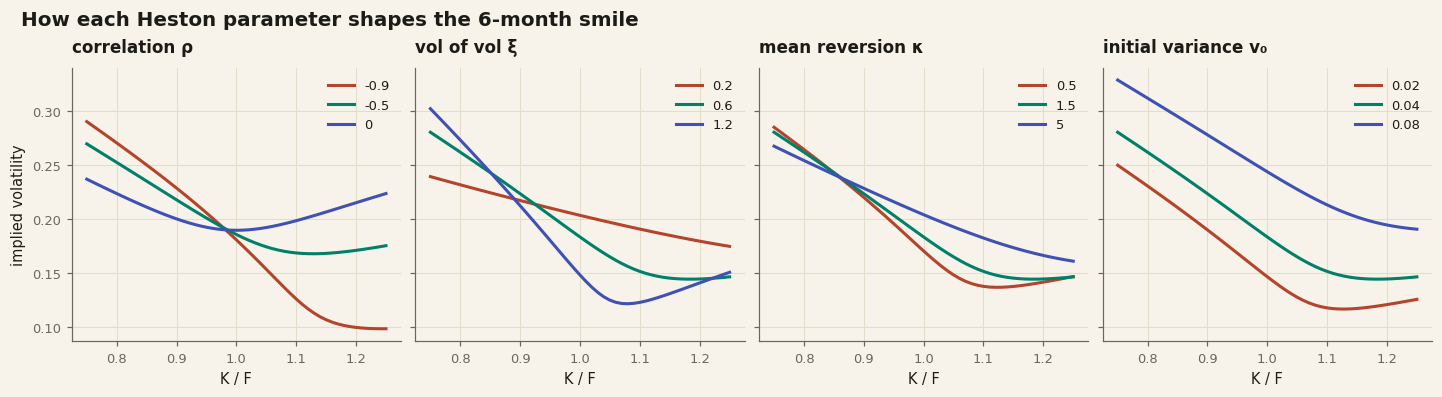

𓋹 PASS  skew grows as ρ becomes more negative and nearly vanishes at ρ = 0 (0.102, 0.049, 0.002)
𓋹 PASS  smile curvature increases with vol of vol ξ


In [3]:
T = 0.5
F = S0 * np.exp((r - q) * T)
moneyness = np.linspace(0.75, 1.25, 51)
panels = {
    "rho": ("correlation ρ", [-0.9, -0.5, 0.0]),
    "xi": ("vol of vol ξ", [0.2, 0.6, 1.2]),
    "kappa": ("mean reversion κ", [0.5, 1.5, 5.0]),
    "v0": ("initial variance v₀", [0.02, 0.04, 0.08]),
}
smiles = {}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5), sharey=True)
for ax, (name, (label, values)) in zip(axes, panels.items(), strict=True):
    for value, color in zip(values, st.SERIES, strict=False):
        m = HestonModel(base.model_copy(update={name: value}))
        iv = m.implied_vol(S0, moneyness * F, T, r, q)
        smiles[name, value] = iv
        ax.plot(moneyness, iv, color=color, label=f"{value:g}")
    ax.set_title(label)
    ax.set_xlabel("K / F")
    ax.legend(title=None, loc="upper right", fontsize=8.5)
axes[0].set_ylabel("implied volatility")
fig.suptitle("How each Heston parameter shapes the 6-month smile", x=0.01, ha="left")
st.save(fig, "heston_smile_anatomy")
plt.show()


def skew(iv):  # implied vol at 90% minus 110% of the forward
    return np.interp(0.9, moneyness, iv) - np.interp(1.1, moneyness, iv)


def curvature(iv):
    return np.interp(0.9, moneyness, iv) + np.interp(1.1, moneyness, iv) - 2 * np.interp(1.0, moneyness, iv)


skews = [skew(smiles["rho", v]) for v in panels["rho"][1]]
st.check(skews[0] > skews[1] > skews[2] and abs(skews[2]) < 0.01,
         f"skew grows as ρ becomes more negative and nearly vanishes at ρ = 0 ({', '.join(f'{s:.3f}' for s in skews)})")
curv = [curvature(smiles["xi", v]) for v in panels["xi"][1]]
st.check(curv[0] < curv[1] < curv[2], "smile curvature increases with vol of vol ξ")

## 3 𓏼 The implied-volatility surface

Short maturities show the steepest skew; as maturity grows, the smile flattens and the
at-the-money level moves from $\sqrt{v_0}$ towards $\sqrt{\theta}$.

Far out of the money at short maturities, prices fall towards $10^{-10}$. The Lewis
integral is accurate to about $10^{-10}$ and prices are floored at their no-arbitrage
bounds, so they are never negative, but an implied volatility backed out of such a price
is only good to a few digits. The surface below stops at $\ln(K/F) = 0.25$, where
one-month prices are still well above that level.

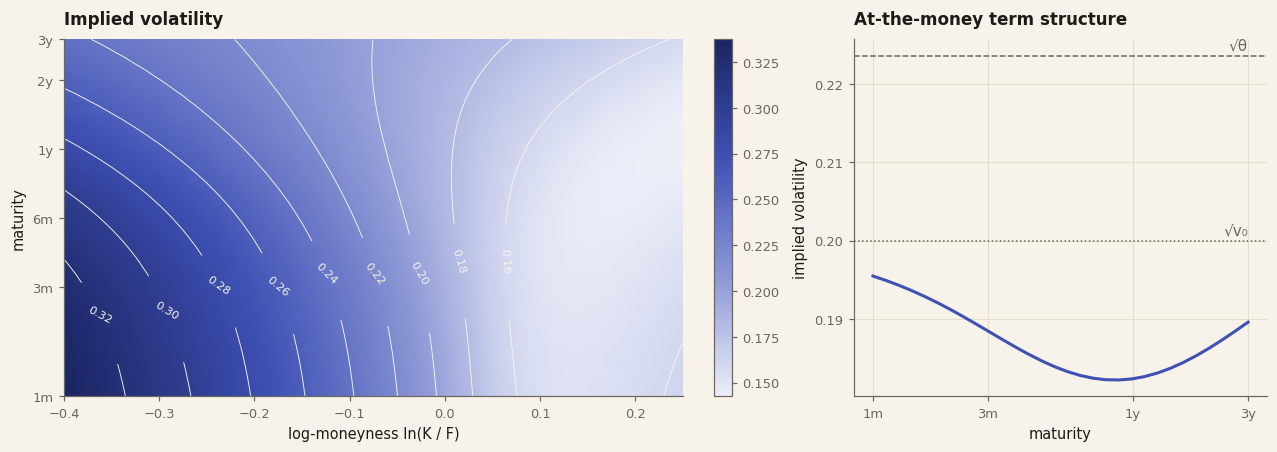

𓋹 PASS  surface inverts everywhere (1590 points)
𓋹 PASS  ATM volatility starts near √v₀ and moves away from it with maturity


In [4]:
mats = np.geomspace(1 / 12, 3, 30)
log_m = np.linspace(-0.4, 0.25, 53)
LM, TT = np.meshgrid(log_m, mats)
FF = S0 * np.exp((r - q) * TT)
surface_iv = model.implied_vol(S0, FF * np.exp(LM), TT, r, q)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1.5, 1]})
mesh = ax1.pcolormesh(log_m, mats, surface_iv, cmap=st.SEQUENTIAL, shading="gouraud")
contours = ax1.contour(log_m, mats, surface_iv, levels=np.arange(0.12, 0.40, 0.02), colors=st.PAPER, linewidths=0.6)
ax1.clabel(contours, fmt="%.2f", fontsize=7.5)
ax1.set_yscale("log")
ax1.set_yticks([1 / 12, 0.25, 0.5, 1, 2, 3], ["1m", "3m", "6m", "1y", "2y", "3y"])
ax1.minorticks_off()
ax1.grid(False)
ax1.set(title="Implied volatility", xlabel="log-moneyness ln(K / F)", ylabel="maturity")
fig.colorbar(mesh, ax=ax1)

atm = surface_iv[:, np.argmin(np.abs(log_m))]
ax2.plot(mats, atm, color=st.INDIGO)
ax2.axhline(np.sqrt(base.v0), color=st.MUTED, ls=":", lw=1)
ax2.axhline(np.sqrt(base.theta), color=st.MUTED, ls="--", lw=1)
ax2.annotate("√v₀", (mats[-1], np.sqrt(base.v0)), xytext=(0, 4), textcoords="offset points", ha="right", color=st.MUTED)
ax2.annotate("√θ", (mats[-1], np.sqrt(base.theta)), xytext=(0, 4), textcoords="offset points", ha="right", color=st.MUTED)
ax2.set_xscale("log")
ax2.set_xticks([1 / 12, 0.25, 1, 3], ["1m", "3m", "1y", "3y"])
ax2.minorticks_off()
ax2.set(title="At-the-money term structure", xlabel="maturity", ylabel="implied volatility")
plt.show()

st.check(not np.isnan(surface_iv).any(), f"surface inverts everywhere ({surface_iv.size} points)")
st.check(abs(atm[0] - np.sqrt(base.v0)) < abs(atm[-1] - np.sqrt(base.v0)),
         "ATM volatility starts near √v₀ and moves away from it with maturity")

## 4 𓏽 Monte Carlo: does QE get the variance right?

The variance $v_T$ has a known law: a scaled non-central chi-squared distribution. Here the
parameters violate the Feller condition, so $v$ spends time near zero, which is where
simple Euler schemes go wrong. With these parameters the exact law puts most of its
mass within $10^{-4}$ of zero; QE represents that mass as an atom at exactly zero, so the
comparison is made on the distribution function, on a log scale.

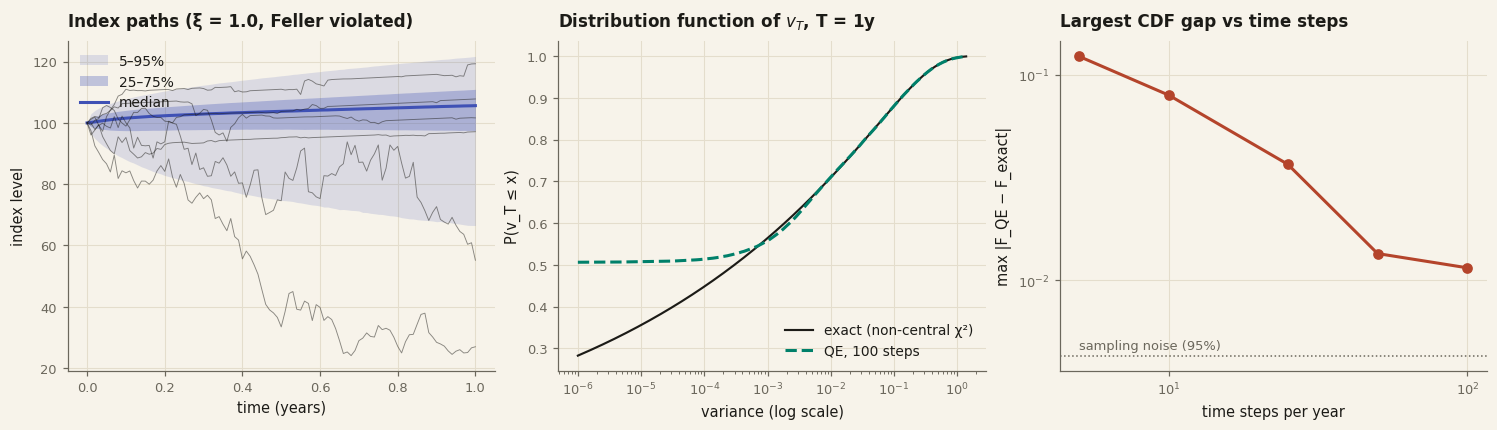

𓋹 PASS  E[v_T] matches the exact law (z = +0.46)
𓋹 PASS  Var[v_T] within 3% of exact (+1.26%)
𓋹 PASS  CDF gap shrinks with steps (0.123 at 5 → 0.012 at 100)
𓋹 PASS  discounted index is a martingale (z = -1.06)


In [5]:
hard = base.model_copy(update={"xi": 1.0, "kappa": 1.0})
T, n_paths = 1.0, 100_000
c = hard.xi**2 * (1 - np.exp(-hard.kappa * T)) / (4 * hard.kappa)
law = stats.ncx2(4 * hard.kappa * hard.theta / hard.xi**2, hard.v0 * np.exp(-hard.kappa * T) / c)
check_grid = np.geomspace(1e-3, 0.5, 200)


def cdf_gap(v_T):
    empirical = np.searchsorted(np.sort(v_T), check_grid, side="right") / len(v_T)
    return np.max(np.abs(empirical - law.cdf(check_grid / c)))


step_counts = [5, 10, 25, 50, 100]
gaps = []
for n_steps in step_counts:
    times, S, v = HestonModel(hard).simulate(S0, T, r, q, n_steps=n_steps, n_paths=n_paths, seed=11)
    gaps.append(cdf_gap(v[:, -1]))
noise = 1.36 / np.sqrt(n_paths)          # 95% Kolmogorov–Smirnov band for this many paths

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13.5, 3.8))
qs = np.quantile(S, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0)
ax1.fill_between(times, qs[0], qs[4], color=st.INDIGO, alpha=0.15, lw=0, label="5–95%")
ax1.fill_between(times, qs[1], qs[3], color=st.INDIGO, alpha=0.30, lw=0, label="25–75%")
ax1.plot(times, qs[2], color=st.INDIGO, label="median")
for path in S[:6]:
    ax1.plot(times, path, color=st.INK, lw=0.6, alpha=0.5)
ax1.set(title=f"Index paths (ξ = {hard.xi}, Feller violated)", xlabel="time (years)", ylabel="index level")
ax1.legend(loc="upper left")

grid = np.geomspace(1e-6, np.quantile(v[:, -1], 0.999), 300)
empirical = np.searchsorted(np.sort(v[:, -1]), grid, side="right") / n_paths
ax2.semilogx(grid, law.cdf(grid / c), color=st.INK, lw=1.4, label="exact (non-central χ²)")
ax2.semilogx(grid, empirical, color=st.VERDIGRIS, ls="--", label="QE, 100 steps")
ax2.set(title="Distribution function of $v_T$, T = 1y", xlabel="variance (log scale)", ylabel="P(v_T ≤ x)")
ax2.legend(loc="lower right")

ax3.loglog(step_counts, gaps, "o-", color=st.OXIDE, label="QE")
ax3.axhline(noise, color=st.MUTED, ls=":", lw=1)
ax3.annotate("sampling noise (95%)", (step_counts[0], noise), xytext=(0, 4), textcoords="offset points", fontsize=8.5, color=st.MUTED)
ax3.set(title="Largest CDF gap vs time steps", xlabel="time steps per year", ylabel="max |F_QE − F_exact|")
ax3.minorticks_off()
st.save(fig, "heston_qe")
plt.show()

vT = v[:, -1]
mean_z = (vT.mean() - c * law.mean()) / (vT.std() / np.sqrt(n_paths))
st.check(abs(mean_z) < 4, f"E[v_T] matches the exact law (z = {mean_z:+.2f})")
st.check(abs(vT.var() / (c**2 * law.var()) - 1) < 0.03, f"Var[v_T] within 3% of exact ({vT.var() / (c**2 * law.var()) - 1:+.2%})")
st.check(gaps[-1] < gaps[0] / 4 and gaps[-1] < 0.015,
         f"CDF gap shrinks with steps ({gaps[0]:.3f} at {step_counts[0]} → {gaps[-1]:.3f} at {step_counts[-1]})")
disc = S[:, -1] * np.exp(-(r - q) * T)
mart_z = (disc.mean() - S0) / (disc.std() / np.sqrt(n_paths))
st.check(abs(mart_z) < 4, f"discounted index is a martingale (z = {mart_z:+.2f})")
del S, v

## 5 𓏾 VIX under Heston, and what Heston gets wrong

VIX² is affine in the variance, so VIX futures and options are one-dimensional integrals.
The futures curve rises or falls towards the long-run level depending on where $v_0$ starts.
The VIX smile is the problem: market VIX smiles slope **up** (calls on volatility are
expensive), but Heston's slopes **down**. Notebook 02 shows Cont–Kokholm getting this right.

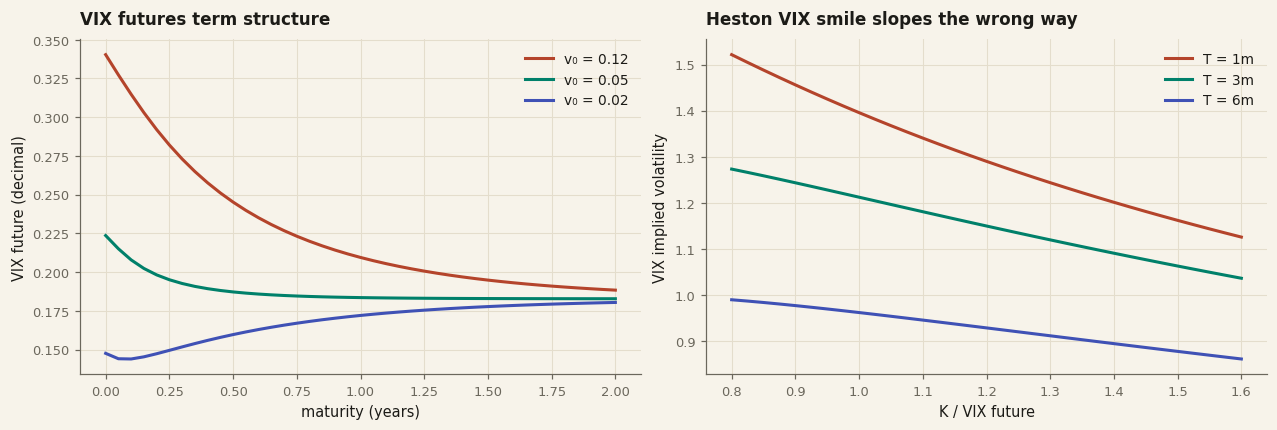

𓋹 PASS  Heston's VIX smile slopes down for every maturity (market smiles slope up)


𓋹 PASS  VIX future matches Monte Carlo E[VIX_T] (z = -1.41)


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8))
fut_T = np.linspace(0, 2, 41)
for v0, color in [(0.12, st.OXIDE), (0.05, st.VERDIGRIS), (0.02, st.INDIGO)]:
    m = HestonModel(base.model_copy(update={"v0": v0}))
    ax1.plot(fut_T, [m.vix_future(t) for t in fut_T], color=color, label=f"v₀ = {v0}")
ax1.set(title="VIX futures term structure", xlabel="maturity (years)", ylabel="VIX future (decimal)")
ax1.legend(loc="upper right")

vix_smiles = {}
for T, color in zip([1 / 12, 0.25, 0.5], st.SERIES, strict=False):
    F_vix = model.vix_future(T)
    K = F_vix * np.linspace(0.8, 1.6, 33)
    prices = model.vix_option_price(K, T, r)
    iv = implied_volatility(prices * np.exp(r * T), F_vix, K, T, 0.0)   # Black-76 on the future
    vix_smiles[T] = iv
    ax2.plot(K / F_vix, iv, color=color, label=f"T = {round(T * 12)}m")
ax2.set(title="Heston VIX smile slopes the wrong way", xlabel="K / VIX future", ylabel="VIX implied volatility")
ax2.legend()
plt.show()

slopes = [np.polyfit(np.linspace(0.8, 1.6, 33)[8:], iv[8:], 1)[0] for iv in vix_smiles.values()]
st.check(all(s < 0 for s in slopes), "Heston's VIX smile slopes down for every maturity (market smiles slope up)")

_, _, v = model.simulate(S0, 0.5, r, q, n_steps=50, n_paths=100_000, seed=3)
a, b = vix_coefficients(base)
vix_mc = np.sqrt(a * v[:, -1] + b)
z = (vix_mc.mean() - model.vix_future(0.5)) / (vix_mc.std() / np.sqrt(len(vix_mc)))
st.check(abs(z) < 4, f"VIX future matches Monte Carlo E[VIX_T] (z = {z:+.2f})")
del v

## 6 𓏿 Calibration round trip

Generate a surface from known parameters, add noise of half a volatility point to each
implied volatility, and calibrate. The fit should come back to the noise level, and the
recovered parameters close to the truth.

In [7]:
true = HestonParameters(v0=0.035, kappa=2.0, theta=0.06, xi=0.7, rho=-0.75)
true_model = HestonModel(true)
cal_mats = np.array([1 / 12, 0.25, 0.5, 1.0, 2.0])
cal_m = np.array([0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.2])
MM, TT = np.meshgrid(cal_m, cal_mats)
FF = S0 * np.exp((r - q) * TT)
KK = MM * FF
types = np.where(MM >= 1, "call", "put")
true_iv = true_model.implied_vol(S0, KK, TT, r, q)
rng = np.random.default_rng(2024)
quote_iv = true_iv + rng.normal(0, 0.005, true_iv.shape)
quotes = bs_price(S0, KK, TT, r, quote_iv, q, option_type=types)
surface = OptionSurface(strike=KK.ravel(), maturity=TT.ravel(), price=quotes.ravel(),
                        option_type=types.ravel(), spot=S0, r=r, q=q)

start = time.perf_counter()
fitted, info = HestonCalibrator(seed=1).calibrate(surface)
elapsed = time.perf_counter() - start

print(f"{'':8}{'true':>10}{'fitted':>10}")
for name in ["v0", "kappa", "theta", "xi", "rho"]:
    print(f"{name:8}{getattr(true, name):>10.4f}{getattr(fitted, name):>10.4f}")
print(f"\nIV RMSE {info['iv_rmse'] * 100:.2f} vol points, {len(surface)} quotes, {elapsed:.1f}s")

              true    fitted
v0          0.0350    0.0351
kappa       2.0000    2.4633
theta       0.0600    0.0561
xi          0.7000    0.7482
rho        -0.7500   -0.7516

IV RMSE 0.46 vol points, 45 quotes, 12.0s


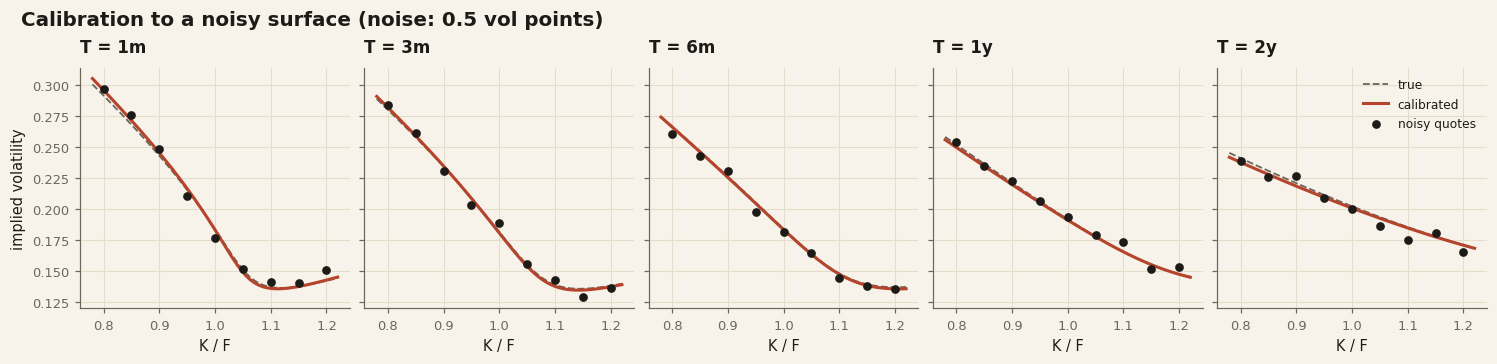

𓋹 PASS  fit error is at the noise level (0.46 vs 0.5 vol points)
𓋹 PASS  v0, θ and ρ recovered within 10% (v0 0.2%, theta 6.5%, rho 0.2%)


In [8]:
fit_model = HestonModel(fitted)
fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.2), sharey=True)
fine = np.linspace(0.78, 1.22, 60)
for ax, T, quote_row in zip(axes, cal_mats, quote_iv, strict=True):
    F = S0 * np.exp((r - q) * T)
    ax.plot(fine, true_model.implied_vol(S0, fine * F, T, r, q), color=st.MUTED, lw=1.2, ls="--", label="true")
    ax.plot(fine, fit_model.implied_vol(S0, fine * F, T, r, q), color=st.OXIDE, label="calibrated")
    ax.scatter(cal_m, quote_row, s=22, color=st.INK, zorder=3, label="noisy quotes")
    ax.set_title(f"T = {round(T * 12)}m" if T < 1 else f"T = {T:g}y")
    ax.set_xlabel("K / F")
axes[0].set_ylabel("implied volatility")
axes[-1].legend(loc="upper right", fontsize=8)
fig.suptitle("Calibration to a noisy surface (noise: 0.5 vol points)", x=0.01, ha="left")
st.save(fig, "heston_calibration")
plt.show()

st.check(info["iv_rmse"] < 0.0075, f"fit error is at the noise level ({info['iv_rmse'] * 100:.2f} vs 0.5 vol points)")
rel = {n: abs(getattr(fitted, n) / getattr(true, n) - 1) for n in ["v0", "theta", "rho"]}
st.check(max(rel.values()) < 0.1, "v0, θ and ρ recovered within 10% (" + ", ".join(f"{n} {e:.1%}" for n, e in rel.items()) + ")")

In [9]:
st.summary()

16/16 checks passed
  𓋹 PASS  Kar–Madan FFT agrees with Lewis up to grid interpolation (max 1.1e-06)
  𓋹 PASS  Cont–Tankov FFT agrees with Lewis up to grid interpolation (max 7.3e-07)
  𓋹 PASS  Monte Carlo agrees with Lewis within 4 s.e. (max |z| = 1.84, 0.4s)
  𓋹 PASS  put–call parity holds
  𓋹 PASS  skew grows as ρ becomes more negative and nearly vanishes at ρ = 0 (0.102, 0.049, 0.002)
  𓋹 PASS  smile curvature increases with vol of vol ξ
  𓋹 PASS  surface inverts everywhere (1590 points)
  𓋹 PASS  ATM volatility starts near √v₀ and moves away from it with maturity
  𓋹 PASS  E[v_T] matches the exact law (z = +0.46)
  𓋹 PASS  Var[v_T] within 3% of exact (+1.26%)
  𓋹 PASS  CDF gap shrinks with steps (0.123 at 5 → 0.012 at 100)
  𓋹 PASS  discounted index is a martingale (z = -1.06)
  𓋹 PASS  Heston's VIX smile slopes down for every maturity (market smiles slope up)
  𓋹 PASS  VIX future matches Monte Carlo E[VIX_T] (z = -1.41)
  𓋹 PASS  fit error is at the noise level (0.46 vs 0.5 vol p